In [268]:
# 01 · Bus Wait Times
#Save all wait times of at most 10 minutes in a list named short_waits. Print the list once after the loop.

In [269]:
wait_times = [6, 14, 10, 3, 18]

In [270]:
short_waits=[]
for wait_time in wait_times:
  if wait_time <=10:
    short_waits.append(wait_time)
print(short_waits)

[6, 10, 3]


In [271]:
# 02A · Count Records on One API Page
#Using the sample bus API response below, print how many bus records appear on this page.

In [272]:
bus_data = {
    "response": {
        "page": 1,
        "pages": 2,
        "results": [
            {"route": "M4", "wait_minutes": 7},
            {"route": "M5", "wait_minutes": 12},
            {"route": "M4", "wait_minutes": 4}
        ]
    }
}

In [273]:
records=bus_data["response"]["results"]
len(records)
print(len(records))

3


In [274]:
# 02B · Combine Records from Two API Pages
#Combine the bus records from page 1 and page 2 into a new list named ,all_records keeping page 1 first. Print the total number of records.

In [275]:
bus_page_2 = {
    "response": {
        "page": 2,
        "pages": 2,
        "results": [
            {"route": "M5", "wait_minutes": 9},
            {"route": "M4", "wait_minutes": 11}
        ]
    }
}

In [276]:
record_1=bus_data['response']["results"]
record_2=bus_page_2['response']["results"]
all_records=[]
all_records.extend(record_1)
all_records.extend(record_2)
print(len(all_records))

5


In [277]:
# 02C · Loop Through API Pages
#Use a for loop to collect the records from every page in bus_pages into a new list named combined_records. Print the total number of records.

In [278]:
bus_pages = [bus_data, bus_page_2]

In [279]:
combined_records=[]
for page in bus_pages:
  combined_records.extend(page["response"]["results"])
print(combined_records)
print(len(combined_records))

[{'route': 'M4', 'wait_minutes': 7}, {'route': 'M5', 'wait_minutes': 12}, {'route': 'M4', 'wait_minutes': 4}, {'route': 'M5', 'wait_minutes': 9}, {'route': 'M4', 'wait_minutes': 11}]
5


In [280]:
#02D: Make a Real API Request
#Print how many forecast dates are in the response.

In [281]:
import requests

url = "https://api.open-meteo.com/v1/forecast"
params = {
    "latitude": 40.81,
    "longitude": -73.96,
    "daily": "temperature_2m_max",
    "timezone": "America/New_York",
    "forecast_days": 3
}

reply = requests.get(url, params=params, timeout=10)
reply.raise_for_status()
weather = reply.json()

In [282]:
print(weather.keys())
print(weather['daily'])
forecast_dates=weather['daily']['time']
print(len(forecast_dates))

dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily'])
{'time': ['2026-11-09', '2026-11-10', '2026-11-11'], 'temperature_2m_max': [14.8, 16.1, 14.2]}
3


In [283]:
#03A · Turn Records into a Table
#Convert combined_records into a DataFrame named bus_df, then print the table.

In [284]:
from pandas._libs.tslibs.offsets import BusinessMonthBegin
import pandas as pd
bus_df=pd.DataFrame(combined_records)
print(bus_df)


  route  wait_minutes
0    M4             7
1    M5            12
2    M4             4
3    M5             9
4    M4            11


In [285]:
#03B · Remove Missing Wait Times
#Drop rows where wait_minutes is missing. Save the result as bus_clean_df and print it.

In [286]:
bus_dirty_df = pd.DataFrame([
    {"route": "M4", "wait_minutes": 7},
    {"route": "M5", "wait_minutes": None},
    {"route": "M4", "wait_minutes": 4},
    {"route": "M5", "wait_minutes": 9}
])

In [287]:
bus_clean_df=bus_dirty_df.dropna(subset="wait_minutes")
print(bus_clean_df)

  route  wait_minutes
0    M4           7.0
2    M4           4.0
3    M5           9.0


In [288]:
#03C · Average Wait Time by Route
#Using bus_clean_df, calculate the average wait_minutes for each route. Save the result as avg_wait_by_route and print it.

In [289]:
avg_wait_by_route=bus_clean_df.groupby("route")["wait_minutes"].mean()
print(avg_wait_by_route)

route
M4    5.5
M5    9.0
Name: wait_minutes, dtype: float64


In [290]:
#04A · Plot Average Wait Time by Route
#Use avg_wait_by_route from 04C to draw a bar chart. Put the bus routes on the x-axis and their average wait times on the y-axis.

<Axes: xlabel='route'>

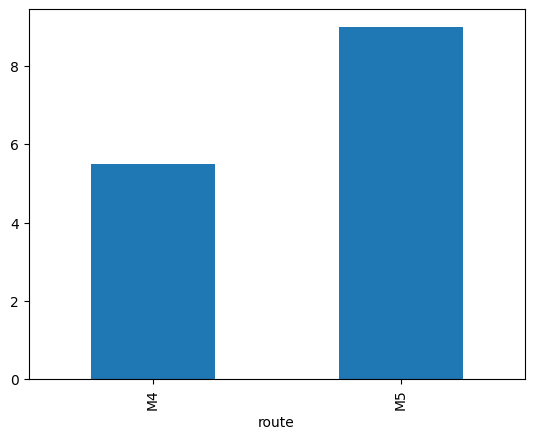

In [291]:
avg_wait_by_route.plot(kind = "bar")

In [292]:
#04B · Add a Title and a Y-Axis Label
#Add a title and a y-axis label to your bar chart from 05A. Use Average Bus Wait by Route as the title and Wait Time (minutes) as the y-axis label.

<Axes: title={'center': 'Average Bus Wait by Route'}, xlabel='route', ylabel='Wait Time(minutes)'>

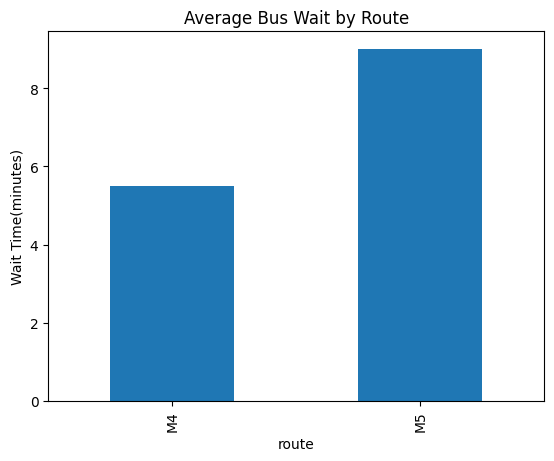

In [293]:
avg_wait_by_route.plot(kind="bar",title="Average Bus Wait by Route",ylabel="Wait Time(minutes)")

In [294]:
#05A · Filter Bus Records with SQL
#From the bus_waits table, show the route and wait_minutes for every record with a wait time of at least 10 minutes.

In [295]:
import sqlite3

conn = sqlite3.connect(":memory:")
bus_df.to_sql("bus_waits", conn, index=False, if_exists="replace")

5

In [298]:
query = """
SELECT route,wait_minutes
FROM bus_waits
WHERE wait_minutes>=10
"""
pd.read_sql_query(query,conn)

,route,wait_minutes
0,M5,12
1,M4,11


In [ ]:
#05B · Average Wait Time by Route
#Using the bus_waits table, show each route and its average wait_minutes. Use all five records.

In [301]:
query="""
SELECT route,AVG(wait_minutes)
FROM bus_waits
GROUP BY route
"""
pd.read_sql_query(query,conn)


,route,AVG(wait_minutes)
0,M4,7.333333
1,M5,10.500000
